In [1]:
!pip install pyDOE

  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18170 sha256=24ba1ebae241d8a41f57c5bc3e2412969dcba6838608c3c3c270f7363ea66aa1
  Stored in directory: /root/.cache/pip/wheels/96/b9/5d/1138ea8c8f212bce6e97ae58847b7cc323145b3277f2129e2b
Successfully built pyDOE


In [2]:
import tensorflow as tf
import numpy as np
from pyDOE import lhs
import matplotlib.pyplot as plt

In [3]:
plt.rcParams.update({'font.size': 14})

### Define the ICs as Fourier series

In [4]:
# Boundaries of the computational domain
xleft, xright = -np.pi, np.pi
t0, tfinal = 0, 0.25

In [5]:
# Wave speed
c = 1

# Maximum number of waves in ICs
max_waves = 5

In [6]:
# How many sensor points to use
N_sensor_points = 100

In [7]:
def u0(x, amplitudes, phases):
  u = 0.0*x
  for i in range(max_waves):
    # Change to sine and cosine instead of sine + phases
    u += amplitudes[i]*tf.sin((i+1)*x + phases[i])
  return u

def u0v(x, amplitudes, phases):
  u = 0.0*x
  for i in range(max_waves):
    u += amplitudes[:,i:i+1]*tf.sin((i+1)*x + phases[:,i:i+1])
  return u

In [14]:
def defineCollocationPoints(N=10000, max_waves=5):

  # Uniform random sampling for PDE points
  tx_min = np.array([t0, xleft])
  tx_max = np.array([tfinal, xright])
  pde_points = tx_min + (tx_max - tx_min)*lhs(2, N)
  t_pde = pde_points[:, 0]
  x_pde = pde_points[:, 1]

  # Initial data sample
  x_points = np.linspace(xleft, xright, N_sensor_points)

  amplitudes = np.random.randn(N, max_waves)
  phases = -np.pi*np.random.rand(N, max_waves) + np.pi/2

  # Generate the data for the branch net
  usensors = np.float32(u0v(np.repeat(np.expand_dims(x_points, axis=0), repeats=N, axis=0), amplitudes, phases).numpy())
  pdes = np.column_stack([t_pde, x_pde, amplitudes, phases]).astype(np.float32)
  print(usensors)
  print(usensors.shape)
  return (pdes, usensors)

In [26]:
N = 20000
(pdes, usensors) = defineCollocationPoints(N, max_waves)

[[-0.10144639 -0.33268598 -0.56334245 ...  0.34924138  0.12710786
  -0.10144639]
 [-0.8871209  -1.088367   -1.2521377  ... -0.48309043 -0.6765053
  -0.8871209 ]
 [-0.07043998 -0.11166453 -0.23045225 ... -0.22993113 -0.11164261
  -0.07043998]
 ...
 [ 0.57755953  0.22164069 -0.20163263 ...  0.93955785  0.8261009
   0.57755953]
 [ 2.375735    2.3057249   2.1792324  ...  2.3280196   2.383866
   2.375735  ]
 [ 0.08215293 -0.35858065 -0.83871    ...  0.6742714   0.43787417
   0.08215293]]
(20000, 100)


### DeepONet model

In [16]:
class PeriodicBCs(tf.keras.layers.Layer):
  def __init__(self, name=None, **kwargs):
    super(PeriodicBCs, self).__init__(name=name, **kwargs)

  def call(self, inputs):
    return tf.concat((tf.cos(inputs), tf.sin(inputs)), axis=1)


# Define the normalization layer
class Normalize(tf.keras.layers.Layer):
  def __init__(self, xmin, xmax, name=None, **kwargs):
    super(Normalize, self).__init__(name=name)
    self.xmin = xmin
    self.xmax = xmax
    super(Normalize, self).__init__(**kwargs)

  def call(self, inputs):
    return 2.0*(inputs-self.xmin)/(self.xmax-self.xmin)-1.0

  def get_config(self):
    config = super(Normalize, self).get_config()
    config.update({'xmin': self.xmin, 'xmax': self.xmax})
    return config

In [17]:
def mlp_network(inp, n_layers, n_units):

  h = inp
  for i in range(n_layers-1):
    h = tf.keras.layers.Dense(n_units, activation='tanh')(h)
  out = tf.keras.layers.Dense(n_units, activation='linear')(h)
  return out

In [18]:
# Architecture
n_units = 40
n_layers = 6

# Branch net
# inp_u = tf.keras.layers.Input(shape=(2*max_waves, ))
inp_u = tf.keras.layers.Input(shape=(N_sensor_points, ))
branch_net = mlp_network(inp_u, n_layers, n_units)

# Pre net
pre_net = mlp_network(inp_u, n_layers, n_units)
scale = tf.keras.layers.Dense(3, use_bias=False)(pre_net)
shift = tf.keras.layers.Dense(3)(pre_net)

# Trunk net
inp_t = tf.keras.layers.Input(shape=(1,))
b_t = Normalize(t0, tfinal)(inp_t)

inp_x = tf.keras.layers.Input(shape=(1,))
periodic_x = PeriodicBCs()(inp_x)

inp_tx = tf.keras.layers.Concatenate()([b_t, periodic_x])

# Apply pre-net to prepared trunk net input
scale_inp_tx = tf.keras.layers.Multiply()([scale, inp_tx])
shift_scale_inp_tx = tf.keras.layers.Add()([shift, scale_inp_tx])

# Actual trunk net
# trunk_net = mlp_network(shift_scale_inp_tx, n_layers, n_units)
trunk_net = mlp_network(inp_tx, n_layers, n_units)

out = tf.keras.layers.Multiply()([branch_net, trunk_net])
out = tf.keras.layers.Dense(1)(out)

model = tf.keras.models.Model([inp_t, inp_x, inp_u], out)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalize_1         │ (None, 1)         │          0 │ input_layer_1[0]… │
│ (Normalize)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ periodic_b_cs       │ (None, 2)         │          0 │ input_layer_2[0]… │
│ (PeriodicBCs)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 3)         │          0 │ normalize_1[0][0… │
│ (Concatenate)       │                   │            │ periodic_b_cs[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 40)        │      4,040 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 40)        │        160 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 40)        │      1,640 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 40)        │      1,640 │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 40)        │      1,640 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 40)        │      1,640 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 40)        │      1,640 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 40)        │      1,640 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 40)        │      1,640 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 40)        │      1,640 │ dense_17[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 40)        │      1,640 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 40)        │      1,640 │ dense_18[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 40)        │          0 │ dense_5[0][0],    │
│ (Multiply)          │                   │            │ dense_19[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 1)         │         41 │ multiply_1[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 20,641 (80.63 KB)

 Trainable params: 20,641 (80.63 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
@tf.function(reduce_retracing=True)
def train_network(pdes, uIn, opt):

  # PDE points
  t, x, amplitude, phase = pdes[:,:1], pdes[:,1:2], pdes[:,2:2+max_waves], pdes[:,2+max_waves:]

  # Outer gradient for tuning network parameters
  with tf.GradientTape() as tape:

    with tf.GradientTape() as tape1:
      tape1.watch(t), tape1.watch(x)
      u = u0v(x, amplitude, phase) + t/tfinal*model([t, x, uIn])
    [ut, ux] = tape1.gradient(u, [t, x])

    # Advection equation
    eqn = ut + ux

    # Loss
    loss = tf.reduce_mean(tf.square(eqn))

  # Model gradients and update
  grads = tape.gradient(loss, model.trainable_variables)
  opt.apply_gradients(zip(grads, model.trainable_variables))

  return loss

In [20]:
def train(pde_points, u_sensors, epochs=10000):

  # Number of ICs and total number of PDE collocation points
  N = pde_points.shape[0]

  # Batch size for PDE points
  batch_size = 1000

  ds_u = tf.data.Dataset.from_tensor_slices(u_sensors)
  ds_pde = tf.data.Dataset.from_tensor_slices(pde_points)

  ds = tf.data.Dataset.zip((ds_pde, ds_u))
  ds = ds.cache().shuffle(N).batch(batch_size)
  ds = ds.prefetch(tf.data.experimental.AUTOTUNE)

  # Optimizer and learning rate to be used
  lr = 1e-3
  opt = tf.keras.optimizers.Adam(lr)

  epoch_loss = np.zeros(epochs)

  # Main training loop
  for i in range(epochs):

    nr_batches = 0

    # Training for that epoch
    for (pdes, usensor) in ds:

      # Train the network
      loss = train_network(pdes, usensor, opt)

      epoch_loss[i] += loss
      nr_batches += 1

    # Get total epoch loss
    epoch_loss[i] /= nr_batches

    if (np.mod(i, 100)==0):
      print(f"Total loss {i}th epoch: {loss: 6.4f}.")

  return epoch_loss

In [21]:
epochs = 8
loss = train(pdes, usensors, epochs)

Total loss 0th epoch:  27.1186.


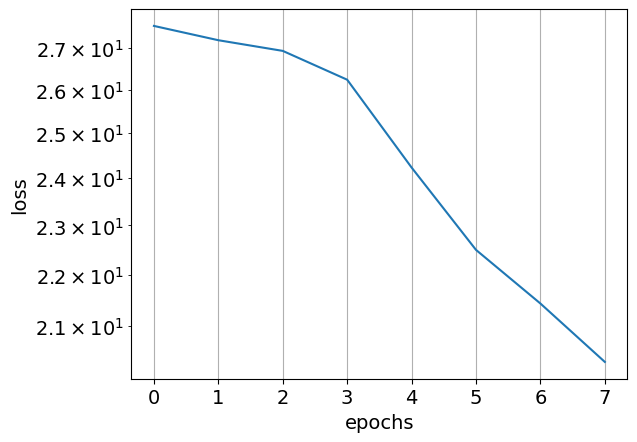

In [22]:
plt.semilogy(range(0, epochs), loss)
plt.xlabel('epochs')
plt.ylabel('loss')
plt.savefig('loss.png')
plt.grid()

In [23]:
# Grid where to evaluate the model
l, n = 50, N_sensor_points
t = np.linspace(t0, tfinal, l)
x = np.linspace(xleft, xright, n)
T, X  = np.meshgrid(t, x, indexing='ij')

In [24]:
# Sample a new IC
amplitudes = np.random.randn(max_waves, 1)
phases = -np.pi*np.random.rand(max_waves, 1) + np.pi/2

x_points = np.linspace(xleft, xright, N_sensor_points)
usensor = u0(np.expand_dims(x_points, axis=0), amplitudes, phases).numpy()
print(usensor.shape)

u = model([np.expand_dims(T.flatten(), axis=1),
           np.expand_dims(X.flatten(), axis=1),
           usensor])[:,0]

u = u0(X.flatten(), amplitudes, phases) + T.flatten()/tfinal*u.numpy()
u = np.reshape(u, (l, n))

(1, 100)


In [ ]:
uTrue = u0(X-c*T, amplitudes, phases)

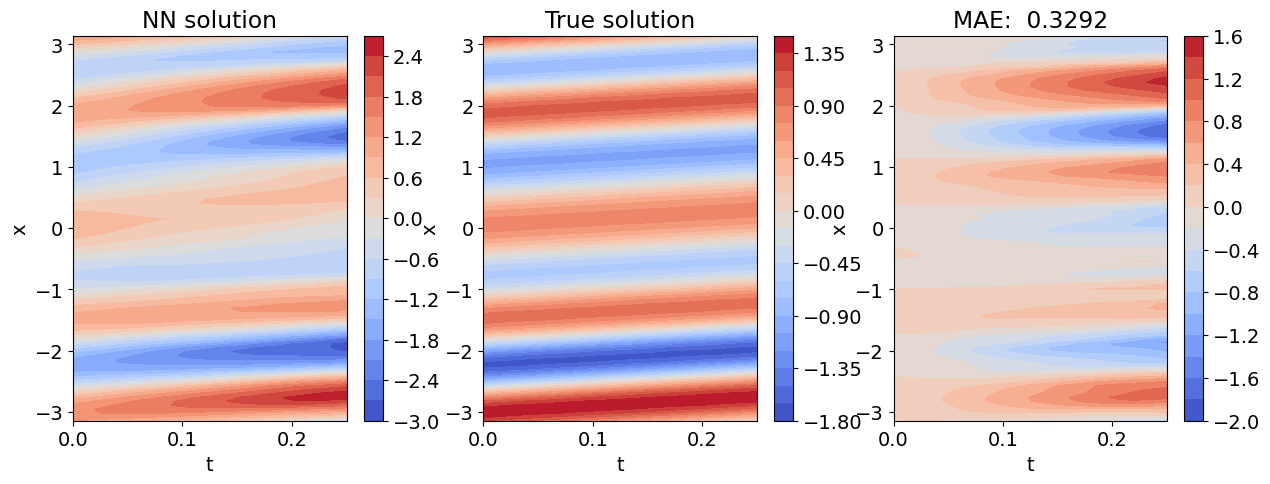

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(131)

plt.contourf(T, X, u, 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('NN solution')
plt.colorbar()


plt.subplot(132)
plt.contourf(T, X, uTrue, 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('True solution')
plt.colorbar()

plt.subplot(133)
plt.contourf(T, X, u-uTrue, 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title(f'MAE: {tf.reduce_mean(tf.abs(u-uTrue)): 2.4f}')
plt.colorbar()

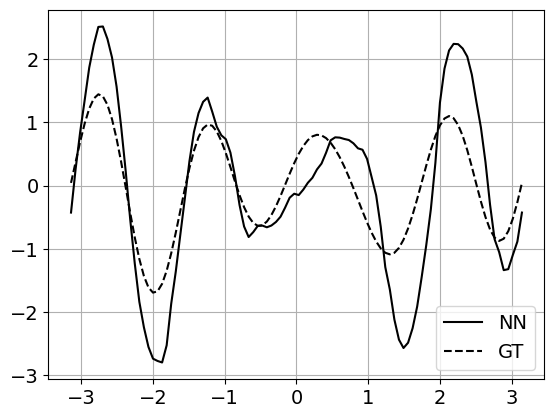

In [ ]:
plt.plot(x, u[-1,],'k')
plt.plot(x, uTrue[-1,],'k--')
plt.grid()
plt.legend(['NN','GT'])

### Time stepping with DeepOnet

In [ ]:
steps = 10

In [ ]:
u = []
for i in range(steps):
  u_c = model([np.expand_dims(T.flatten(), axis=1),
               np.expand_dims(X.flatten(), axis=1),
               usensor])[:,0]

  u_c = np.reshape(u_c, (l, n))

  # Reconstruct solution
  uinit = np.repeat(usensor, repeats=l, axis=0)

  # For form u(t,x) = u0(x) + t/tf*v(t,x)
  print(uinit.shape, u_c.shape)
  u_c = uinit + T/tfinal*u_c

  # # For form u(t,x) = u0(x)*(1-t/tf) + t/tf*v(t,x)
  # u_c = uinit*(1-T/tfinal) + T/tfinal*u_c
  u.append(u_c[:-1,])

  # Next initial condition
  usensor = u_c[-1:,:]

u = np.concatenate(u)

(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)
(50, 100) (50, 100)


In [ ]:
# Exact solution
l, n = 50, N_sensor_points
t = np.linspace(t0, steps*tfinal, steps*(l-1))
x = np.linspace(xleft, xright, n)
TAll, XAll  = np.meshgrid(t, x, indexing='ij')

uTrue = u0(XAll-c*TAll, amplitudes, phases)

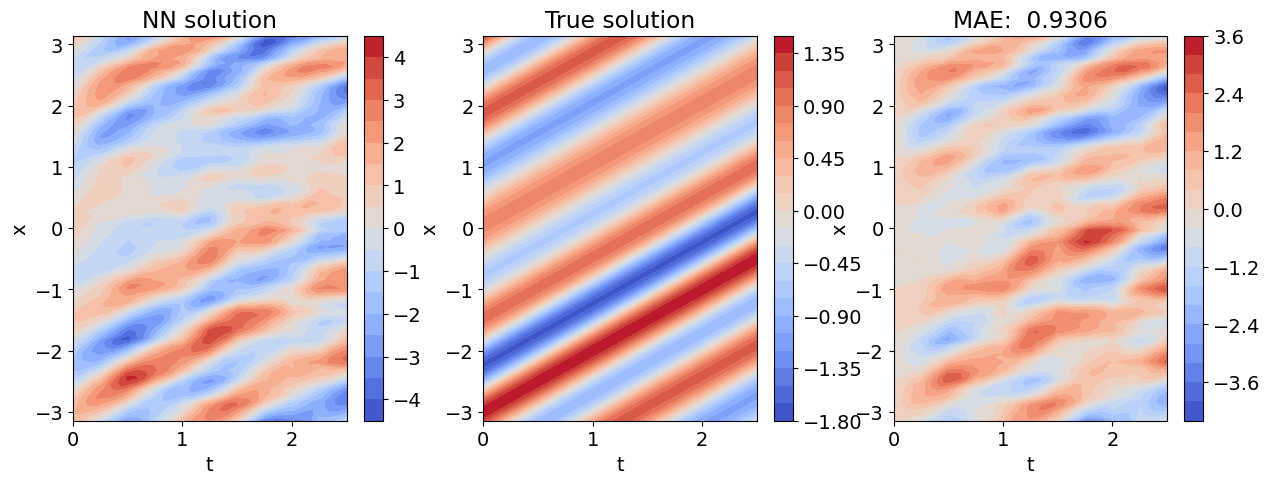

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(131)

plt.contourf(TAll, XAll, u, 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('NN solution')
plt.colorbar()


plt.subplot(132)
plt.contourf(TAll, XAll, uTrue, 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('True solution')
plt.colorbar()

plt.subplot(133)
plt.contourf(TAll, XAll, u-uTrue, 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title(f'MAE: {tf.reduce_mean(tf.abs(u-uTrue)): 2.4f}')
plt.colorbar()

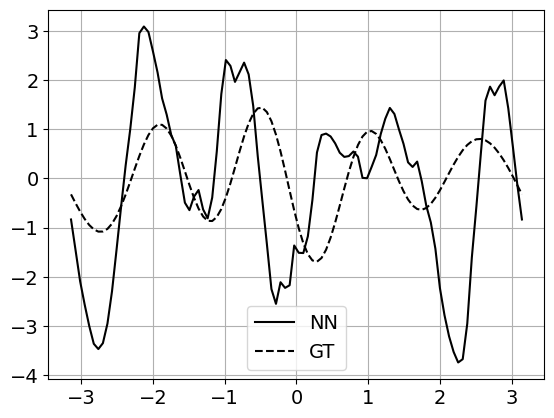

In [ ]:
plt.plot(x, u[-1,],'k')
plt.plot(x, uTrue[-1,],'k--')
plt.grid()
plt.legend(['NN','GT'])